<a href="https://colab.research.google.com/github/christy62/Machine-Learning-Project---Digit-Recognition/blob/main/training_ml_digit_recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import math
import pandas as pd
import matplotlib.pyplot as plt
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"

np.int64(7)

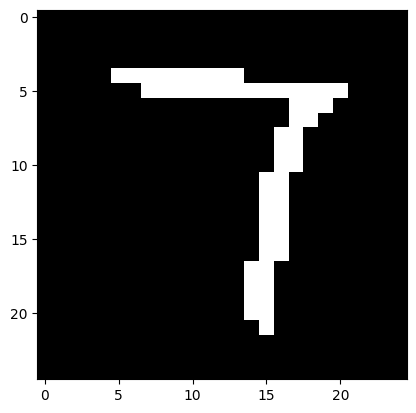

In [ ]:
train_df = pd.read_csv("/content/digit_binary_data.csv")
train_images = (train_df.iloc[:,:-1].values).astype('float32')
train_labels = train_df['label'].values
train_images = train_images.reshape(train_images.shape[0], 25, 25)
plt.imshow(train_images[798].squeeze(), cmap=plt.get_cmap('gray'))
train_labels[798]

In [ ]:
import torch.nn as nn
import torch.optim as optim
class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()
        self.fc1 = nn.Linear(25 * 25, 128)  # Input layer (flattened 28x28 image)
        self.relu = nn.ReLU()             # Activation function
        self.fc2 = nn.Linear(128, 10)     # Output layer (10 classes for digits 0-9)

    def forward(self, x):
        x = x.view(-1, 25 * 25)  # Flatten the image # one-dimensional
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

model = SimpleNN()

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [ ]:
from torch.utils.data import DataLoader, Dataset

class DigitDataset(Dataset):
    def __init__(self, images, labels):        #constructor
        self.images = torch.from_numpy(images)
        self.labels = torch.from_numpy(labels)

    def __len__(self):     #length - here, 800
        return len(self.labels)

    def __getitem__(self, idx):        #give idx = 0, gives the 0th image and 0th label
        return self.images[idx], self.labels[idx]





num_epochs = 1000
train_dataset = DigitDataset(train_images, train_labels)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

for epoch in range(num_epochs):
    model.train() # Set model to training mode
    for batch_idx, (data, target) in enumerate(train_loader):
        optimizer.zero_grad() # Clear gradients
        output = model(data)  # Forward pass
        loss = criterion(output, target) # Calculate loss
        loss.backward()       # Backward pass (compute gradients)
        optimizer.step()      # Update weights

        if batch_idx % 100 == 0:
            print(f'Epoch: {epoch+1}, Batch: {batch_idx}/{len(train_loader)}, Loss: {loss.item():.4f}')

Epoch: 1, Batch: 0/13, Loss: 0.0010
Epoch: 2, Batch: 0/13, Loss: 0.0009
Epoch: 3, Batch: 0/13, Loss: 0.0009
Epoch: 4, Batch: 0/13, Loss: 0.0007
Epoch: 5, Batch: 0/13, Loss: 0.0008
Epoch: 6, Batch: 0/13, Loss: 0.0009
Epoch: 7, Batch: 0/13, Loss: 0.0007
Epoch: 8, Batch: 0/13, Loss: 0.0009
Epoch: 9, Batch: 0/13, Loss: 0.0011
Epoch: 10, Batch: 0/13, Loss: 0.0009
Epoch: 11, Batch: 0/13, Loss: 0.0008
Epoch: 12, Batch: 0/13, Loss: 0.0010
Epoch: 13, Batch: 0/13, Loss: 0.0008
Epoch: 14, Batch: 0/13, Loss: 0.0007
Epoch: 15, Batch: 0/13, Loss: 0.0005
Epoch: 16, Batch: 0/13, Loss: 0.0007
Epoch: 17, Batch: 0/13, Loss: 0.0006
Epoch: 18, Batch: 0/13, Loss: 0.0007
Epoch: 19, Batch: 0/13, Loss: 0.0008
Epoch: 20, Batch: 0/13, Loss: 0.0005
Epoch: 21, Batch: 0/13, Loss: 0.0006
Epoch: 22, Batch: 0/13, Loss: 0.0006
Epoch: 23, Batch: 0/13, Loss: 0.0007
Epoch: 24, Batch: 0/13, Loss: 0.0007
Epoch: 25, Batch: 0/13, Loss: 0.0007
Epoch: 26, Batch: 0/13, Loss: 0.0008
Epoch: 27, Batch: 0/13, Loss: 0.0006
Epoch: 28,

In [ ]:
model.eval() # Set model to evaluation mode
train_dataset = DigitDataset(train_images, train_labels)
test_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
correct = 0
total = 0
with torch.no_grad(): # Disable gradient calculation during evaluation
    for data, target in test_loader:
        output = model(data)
        _, predicted = torch.max(output.data, 1) # Get predicted class
        total += target.size(0)
        correct += (predicted == target).sum().item()

accuracy = 100 * correct / total
print(f'Accuracy on the test set: {accuracy:.2f}%')

In [ ]:
output = model(torch.from_numpy(train_images[798].squeeze()).unsqueeze(0))
_, predicted = torch.max(output.data, 1) # Get predicted class
print(predicted)

tensor([7])


In [ ]:
train_images[0]

array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 1., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 1., 1., 0., 0.,
        1., 1., 1., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 0., 0., 0., 0., 0.,
        0., 1., 1., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 0., 0., 0., 0., 0., 0.,
        0., 0., 1., 1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 1., 1., 1., 0., 0., 0., 0., 0., 

Accuracy on the test set: 89.38%


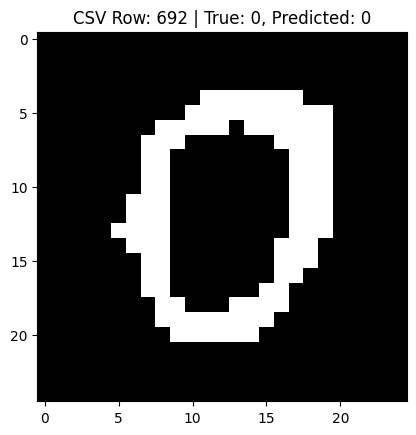

In [ ]:
import torch
from torch.utils.data import random_split, DataLoader
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import matplotlib.pyplot as plt

# ===== Load dataset =====
train_df = pd.read_csv("/content/digit_binary_data.csv")
train_images = (train_df.iloc[:, :-1].values).astype('float32')
train_labels = train_df['label'].values

# reshape into (N, 25, 25)
train_images = train_images.reshape(train_images.shape[0], 25, 25)

# ===== Custom Dataset =====
from torch.utils.data import DataLoader, Dataset

class DigitDataset(Dataset):
    def __init__(self, images, labels):
        self.images = torch.from_numpy(images)
        self.labels = torch.from_numpy(labels)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return self.images[idx], self.labels[idx]

full_dataset = DigitDataset(train_images, train_labels)


# ===== Sequential 80-20 split =====
train_size = int(0.8 * len(full_dataset))
train_dataset = torch.utils.data.Subset(full_dataset, range(0, train_size))
test_dataset  = torch.utils.data.Subset(full_dataset, range(train_size, len(full_dataset)))


train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=64, shuffle=False)

# ===== Define Model =====
class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()
        self.fc1 = nn.Linear(25 * 25, 128)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = x.view(-1, 25 * 25)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

model = SimpleNN()

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# ===== Training loop (example, short) =====
num_epochs = 5


for epoch in range(num_epochs):
    model.train()
    for batch_idx, (data, target) in enumerate(train_loader):
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()
    #print(f"Epoch {epoch+1}, Loss: {loss.item():.4f}")
    if batch_idx % 100 == 0:
        print(f'Epoch: {epoch+1}, Batch: {batch_idx}/{len(train_loader)}, Loss: {loss.item():.4f}')

# ===== Accuracy on test set =====
model.eval()
correct, total = 0, 0
with torch.no_grad():
    for data, target in test_loader:
        output = model(data)
        _, predicted = torch.max(output.data, 1)
        total += target.size(0)
        correct += (predicted == target).sum().item()

print(f'Accuracy on the test set: {100 * correct / total:.2f}%')

# ===== Pick one test sample by index =====
# ===== Pick one test sample by index =====
idx = 50  # change this between 0 and len(test_dataset)-1
image, label = test_dataset[idx]
label = int(label)

# Find the original CSV row index
csv_index = test_dataset.indices[idx]  # this maps back to train_df
true_label_from_csv = train_df.iloc[csv_index, -1]

# predict
with torch.no_grad():
    output = model(image.unsqueeze(0))  # add batch dimension
    _, predicted = torch.max(output.data, 1)
    predicted = int(predicted.item())

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"CSV Row: {csv_index+2} | True: {true_label_from_csv}, Predicted: {predicted}")
plt.show()



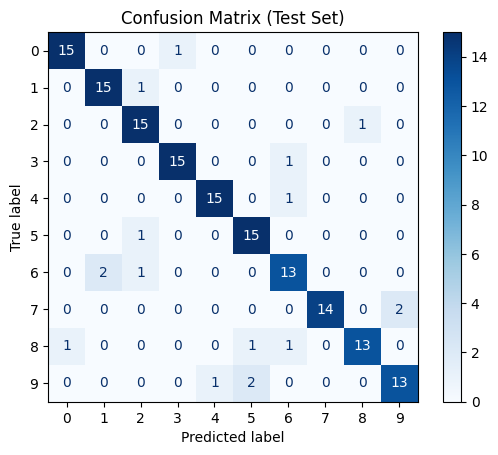

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

# ===== Collect predictions and true labels =====
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for data, target in test_loader:
        output = model(data)
        _, predicted = torch.max(output.data, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(target.cpu().numpy())

# ===== Compute confusion matrix =====
cm = confusion_matrix(all_labels, all_preds)

# ===== Plot =====
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.arange(10))
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix (Test Set)")
plt.show()
